### **Vector and Dot Product**

___

**V1 (ทฤษฎี + โค้ด) dot product และ cosine similarity — อ่าน ThinkDSP บทที่ 6 ช่วงต้น (หัวข้อ Synthesis และ Analysis)**
  - **ทำ:**
    - สร้าง notebook ใหม่ `notebooks/04_Signals_as_Vectors.ipynb`
    - เขียน `dot_loop(a, b)` ด้วย for loop (คูณทีละคู่แล้วบวก) → ทดสอบ `[1, 2, 3]` กับ `[4, 5, 6]` แล้วเทียบกับ `np.dot`
    - สร้างไฟล์ `dsp/similarity.py` มีฟังก์ชัน `cosine_similarity(a, b)` พร้อม docstring ถ้าเวกเตอร์ใดยาวเป็น 0 ให้คืน `0.0`
    - ทดสอบกับตัวเลขที่รู้คำตอบก่อนใช้จริง: `[1,0]·[0,1]`, `[1,2,3]·[2,4,6]`, `[1,0]·[-1,0]`, `[1,1]·[1,0]`, `[0,0]·[1,2]`
    - สร้าง `song = np.array([0.2, 0.5, 0.1])` กับ `loud = 3 * song` → print ทั้ง `np.dot(song, song)`, `np.dot(song, loud)` และ cosine similarity ของ `song` กับ `loud`
    - **เครื่องมือใหม่:** `np.dot([1, 1], [2, 3])` → 5 และ `np.linalg.norm([3, 4])` → 5.0 (ความยาวเวกเตอร์ $\sqrt{3^2+4^2}$)
  - **ตอบ:**
    1. cosine similarity เท่ากับ 1, 0 และ −1 หมายถึงเวกเตอร์ชี้ทิศแบบไหน (ตอบสั้น ๆ ข้อละ 1 ประโยค) \
    cosine similarity เท่ากับ 1 จะหมายถึง เวกเตอร์ทั้งสองตัวชี้ไปในทิศทางเดียวกัน \
    cosine similarity เท่ากับ 0 จะหมายถึง เวกเตอร์ทั้งสองตัวจะตั้งฉากซึ่งกันและกัน (Orthogonality) \
    cosine similarity เท่ากับ -1 จะหมายถึง เวกเตอร์ทั้งสองตัวชี้ไปในทิศทางตรงกันข้ามกัน 

    2. ถ้า `loud` คือเพลงเดิมที่เปิดดังขึ้น 3 เท่า ทำไมระบบแนะนำเพลงควรใช้ cosine similarity แทน dot product
    เพราะการใช้งาน Cosine Similarity เป็นค่าสำหรับการบอกว่าเวกเตอร์ 2 ตัว ทำมุมซึ่งกันและกันเท่าไหร่ ในขณะที่ dot product ค่าจะเพี้ยนมากขึ้นหากมีการขยายเวกเตอร์ขึ้นไป เพราะ จะทำให้ค่าของ dot product มากขึ้นตาม

  - **เสร็จเมื่อ:** `dot_loop` ได้ 32 เท่ากับ `np.dot` และผลทดสอบ 5 คู่ได้ 0, 1, −1, ≈0.7071, 0 ตามลำดับ (เช็คด้วย `np.isclose`) dot ของ song ได้ 0.3 กับ 0.9 แต่ cosine ได้ 1.0

In [1]:
%load_ext autoreload 
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import sys, os
from IPython.display import Audio
sys.path.insert(0, os.path.abspath(".."))

from dsp.similarity import cosine_similarity
from dsp.signal_generator import make_time, create_sin

In [2]:
# โปรแกรมคำนวณ Dot Product เปรียบเทียบกับ np.dot
a = np.array([1,2,3])
b = np.array([4,5,6])

def dot_loop(vec_a, vec_b) -> float:
    """
        Calculates the dot product of two vectors.

        Args:
            vec_a: first input vector
            vec_b: second input vector

        Returns:
            The scalar dot product of `vec_a` and `vec_b`

        Raises:
            ValueError: If `vec_a` and `vec_b` do not have the same length.
    """

    if len(vec_a) != len(vec_b):
        raise ValueError(
            f"Vector lengths must be equal: got {len(vec_a)} and {len(vec_b)}."
        )
    
    return sum(a*b for a,b in zip(vec_a, vec_b))

print(f"Scalar dot product is {dot_loop(a,b)}")
print(f"Scalar dot product with np.dot is {np.dot(a,b)}")


Scalar dot product is 32
Scalar dot product with np.dot is 32


In [3]:
song = np.array([0.2, 0.5, 0.1])
loud = 3 * song

print(f"Scalar product between song and song: {np.dot(song, song)}")
print(f"Scalar product between song and loud : {np.dot(song, loud)}")
print(f"Cosine Similarity between song and loud : {cosine_similarity(song, loud):.2f}")
    

Scalar product between song and song: 0.30000000000000004
Scalar product between song and loud : 0.9
Cosine Similarity between song and loud : 1.00


**[ ] V2 (โค้ด + หู) sine ต่างความถี่ "ตั้งฉาก" กัน**
  - **ทำ:**
    - `sr = 8000` สร้าง `t` ยาว 1 วินาทีด้วย `make_time` → `len(t)` ได้ 8000
    - หา cosine similarity (จาก V1) ของ 4 คู่: (ก) sine 440 กับ sine 440 (ข) sine 440 กับ sine 880 (ค) sine 440 กับ sine 440 เฟส $\pi/2$ (ง) sine 440 กับ sine 445
    - ทำคู่ (ง) ซ้ำ แต่ใช้ `t` ยาวแค่ 0.05 วินาที → print เทียบกับตอน 1 วินาที
    - ฟัง sine 440 + sine 445 ยาว 2 วินาที ด้วย `Audio(..., rate=sr)` แล้วนับว่าเสียงวูบวาบกี่ครั้งต่อวินาที
  - **ตอบ:**
    1. ใน 1 วินาที 440 Hz กับ 880 Hz ครบกี่รอบ และทำไมพอคูณกันทีละ sample แล้วบวก ค่าบวกกับค่าลบจึงหักล้างกันจนเหลือ 0 \
      * ใน 1 วินาที 440 Hz จะครบ 440 รอบ และ 880 Hz จะครบ 880 รอบหรือมีความถี่มากกว่า 2 เท่า ซึ่ง 1 รอบบวกของ 440 จะประกอบด้วยรอบบวกและลบของ 880 ผลคูณจึงมีทั้งค่าบวกและลบที่ขนาดเท่ากันพอดี บวกรวมแล้วหักล้างกันเหลือ 0 คำตอบจึงเป็น 0
    2. คู่ (ง) ทำไมได้ ≈0 ที่ 1 วินาที แต่ได้ ≈0.63 ที่ 0.05 วินาที (ใบ้: ความถี่ต่างกัน 5 Hz ใน 0.05 วินาทีสองคลื่น "เลื่อนออกจากกัน" ได้กี่รอบ) 
      * 440 และ 445 ต่างกัน 5 Hz ใน 1 วินาทีจึงเลื่อนออกจากกันครบ 5 รอบ ส่งผลให้มีช่วงที่ตรงกัน (ผลคูณบวก) และช่วงที่สวนกัน (ผลคูณลบ) มีปริมาณพอ ๆ กัน จึงหักล้างกันเป็น 0 แต่ในช่วงเวลา 0.05 วินาทีเลื่อนห่างกันไม่ถึง 1 รอบ หรือเท่ากับ 0.25 รอบ ผลคูณจึงเป็นบวกเสียส่วนใหญ่ ได้ 0.63
    3. เสียงวูบวาบกี่ครั้งต่อวินาที และตัวเลขนี้เกี่ยวกับ 445 − 440 อย่างไร
    ได้ยินเสียงวูบวาบประมาณ 5 ครั้งต่อวินาที เท่ากับ 445 - 440 = 5 Hz เพราะทุกครั้งที่ 2 คลื่นตรงกันเสียงจะเสริมกันจนดัง และเมื่อสวนกันจะหักล้างกันจนเบา ซึ่งเกิดขึ้น 5 รอบต่อวินาที 
    
  - **เสร็จเมื่อ:** (ก) ได้ 1.0, (ข) และ (ค) ได้ |ค่า| < 0.01, (ง) ได้ |ค่า| < 0.01 ที่ 1 วินาที และ ≈0.63 ที่ 0.05 วินาที, มีเซลล์ Audio 1 ตัว และตอบครบ 3 ข้อ

In [4]:
sr = 8000
t = make_time(0, 1, sr)
t_short = make_time(0, 0.05, sr)
t_long = make_time(0, 2, sr)
sine_440 = create_sin(1, 440, t)
sine_440_t_2 = create_sin(1, 440, t_short)
sine_445 = create_sin(1, 445, t)
sine_445_t_2 = create_sin(1, 445, t_short)
sine_880 = create_sin(1, 880, t)
phase_sine_440 = create_sin(1, 440, t, np.pi/2)

# Create name and signals for zip 
name_signal = [440, 445, 880, "440 phase π/2"]  
signals = [sine_440, sine_445, sine_880, phase_sine_440]   

if len(t) == 8000:
    print(f'len(t) is equal 8000.')

# Loop for print each Cosine Similarity between Sine 440 with those signals (list)
for name, signal in zip(name_signal, signals):
    print(f"Cosine Similarity between 440 and {name} : {cosine_similarity(sine_440, signal):.2f}")


len(t) is equal 8000.
Cosine Similarity between 440 and 440 : 1.00
Cosine Similarity between 440 and 445 : -0.00
Cosine Similarity between 440 and 880 : 0.00
Cosine Similarity between 440 and 440 phase π/2 : -0.00


In [5]:
print(f'Cosine similarity between 440 and 445 within 1 second : {cosine_similarity(sine_440, sine_445):.2f}')
print(f'Cosine similarity between 440 and 445 within 0.05 second : {cosine_similarity(sine_440_t_2, sine_445_t_2):.2f}')

Cosine similarity between 440 and 445 within 1 second : -0.00
Cosine similarity between 440 and 445 within 0.05 second : 0.63


In [6]:
combined_signal = create_sin(1, 440, t_long) + create_sin(1, 445, t_long)
Audio(combined_signal, rate=sr)

**V3 (โค้ด) ใช้ dot product เป็น "เครื่องตรวจจับความถี่" (DFT ฉบับย่อ)**
  - **ทำ:**
    - ใช้ `t` 1 วินาทีจาก V2 สร้าง `x = 0.5·sin(220 Hz) + 0.3·sin(660 Hz) + 0.2·sin(1100 Hz)`
    - สร้างความถี่ที่จะตรวจ `freqs = np.arange(100, 1201, 10)` → `len(freqs)` ได้ 111
    - ใช้ loop หรือ list comprehension: แต่ละ `f` ใน `freqs` สร้าง sine แอมพลิจูด 1 ที่ความถี่ `f` แล้วคำนวณ `2 * np.dot(x, probe) / len(t)` → เก็บเป็น array `amps`
    - พล็อต `amps` เทียบ `freqs` ด้วย `plt.stem` (แกน x = Hz, แกน y = แอมพลิจูดที่ประมาณได้)
    - เปลี่ยนเฉพาะ 660 Hz ให้มีเฟส $\pi/2$ แล้วทำ loop ซ้ำ → print ค่าที่ 660 Hz
    - ลอง probe ที่ 660 Hz ใหม่ แต่ใช้ sine เฟส $\pi/2$ เป็น probe แทน → print ค่า
  - **เครื่องมือใหม่:** `plt.stem([1, 2, 3], [0, 5, 2])` วาดเส้นตั้งพร้อมจุดที่ปลาย เหมาะกับ "ค่าต่อความถี่"
  - **ใบ้:** เลข 2 ในสูตรมาจาก sine แอมพลิจูด 1 dot กับตัวเองได้ N/2 (ดูคู่ (ก) ของ V2 ถ้าใช้ `np.dot` ตรง ๆ จะได้ 4000) ลองเช็คก่อน: `0.5·sin(220)` ผ่านสูตรนี้ควรได้ 0.5
  - **ตอบ:**
    1. กราฟมียอดที่ความถี่ไหนบ้าง สูงเท่าไร ตรงกับที่ใส่ไว้ใน `x` ไหม และทำไมความถี่อื่นได้ ≈0 (อ้างผล V2)
    * กราฟมียอดความถี่ที่ประมาณ 220 Hz, 660 Hz และ 1100 Hz สูง 0.5, 0.3, 0.2 ตามลำดับ ซึ่งตรงกับค่า x ที่ได้มีการใส่ลงไป และที่ความถี่อื่น ๆ ได้ประมาณ 0 เป็นเพราะว่า ความถี่ที่ตรงกันจะเสริมกันทำให้เกิดแอมพลิจูดที่สูงขึ้นในขณะที่ความถี่ที่สวนทางกันจะทำให้หักล้างกันจนเหลือ 0 และนี่คือ Concept ของการทำ Discrete Fourier Transform
    2. หลังเปลี่ยนเฟส ยอด 660 Hz หายไปเพราะอะไร และ probe แบบไหนจับมันได้ → ถ้าไม่รู้เฟสล่วงหน้า ควรใช้ probe กี่แบบต่อหนึ่งความถี่
    หลังเปลี่ยนเฟสยอด 660 Hz หายไปเพราะว่าความถี่ 660 Hz มีการเลื่อนเฟสออกไป $\frac{\pi}{2}$ ส่งผลให้เราไม่สามารถใช้คลื่น Sine ที่ไม่มีเฟสมาตรวจจับได้ เพราะ เฟสไม่ตรงกัน และ probe ที่สามารถตรวจจับได้จะต้องมีเฟสตรงกันนั่นคือ $\frac{\pi}{2}$ ตามการทดลองในกราฟที่ 3 ถ้าไม่รู้เฟสล่วงหน้าก็ควรใช้ probe 2 แบบต่อหนึ่งความถี่ คือ sin และ cos 
  - **เสร็จเมื่อ:** `amps` ที่ 220, 660, 1100 Hz ได้ 0.5, 0.3, 0.2 (เช็คด้วย `np.isclose`) ความถี่อื่น |ค่า| < 1e-6, หลังเปลี่ยนเฟสค่าที่ 660 Hz |ค่า| < 1e-6 และ probe เฟส $\pi/2$ ได้ 0.3, มีกราฟ stem 1 รูป และตอบครบ 2 ข้อ

111


<StemContainer object of 3 artists>

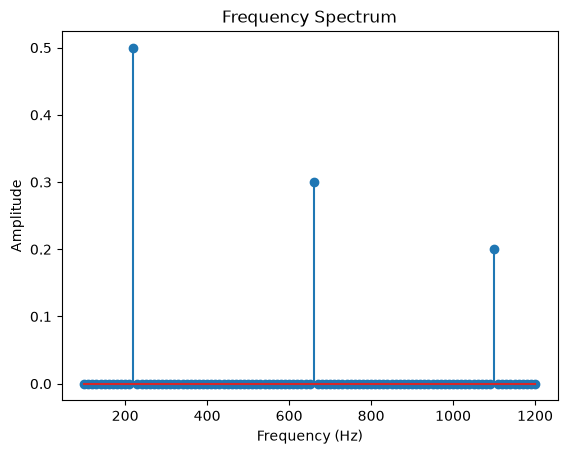

In [7]:
x = create_sin(0.5, 220, t) + create_sin(0.3, 660, t) + create_sin(0.2, 1100, t)
freqs = np.arange(100, 1201, 10)

print(len(freqs))

signals = []
amps = []
for f in freqs:
   signals.append(create_sin(1, f, t))
   amps.append((2*np.dot(x, create_sin(1, f, t)))/len(t)) 

fig, ax = plt.subplots()
ax.set(xlabel="Frequency (Hz)", ylabel="Amplitude", title="Frequency Spectrum")
plt.stem(freqs, amps)

111


<StemContainer object of 3 artists>

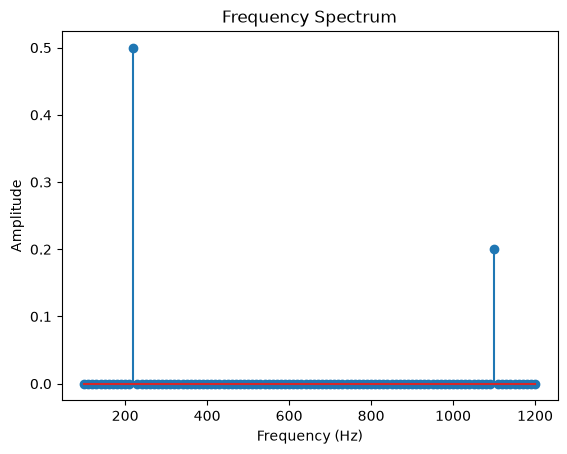

In [8]:
x = create_sin(0.5, 220, t) + create_sin(0.3, 660, t, np.pi/2) + create_sin(0.2, 1100, t)
freqs = np.arange(100, 1201, 10)

print(len(freqs))

signals = []
amps = []
for f in freqs:
   signals.append(create_sin(1, f, t))
   amps.append((2*np.dot(x, create_sin(1, f, t)))/len(t)) 

fig, ax = plt.subplots()
ax.set(xlabel="Frequency (Hz)", ylabel="Amplitude", title="Frequency Spectrum")
plt.stem(freqs, amps)

111


<StemContainer object of 3 artists>

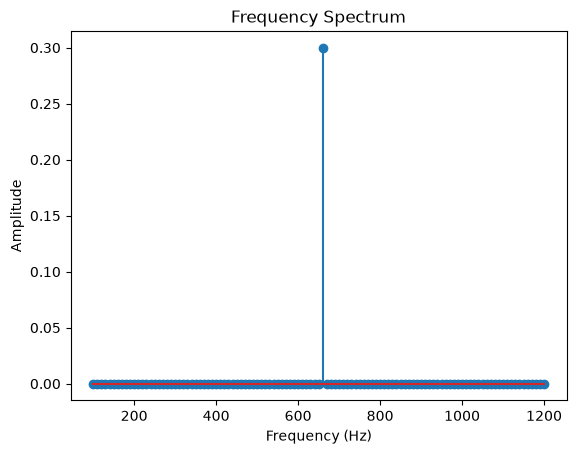

In [9]:
x = create_sin(0.5, 220, t) + create_sin(0.3, 660, t, np.pi/2) + create_sin(0.2, 1100, t)
freqs = np.arange(100, 1201, 10)

print(len(freqs))

signals = []
amps = []
for f in freqs:
   signals.append(create_sin(1, f, t, np.pi/2))
   amps.append((2*np.dot(x, create_sin(1, f, t, np.pi/2)))/len(t)) 

fig, ax = plt.subplots()
ax.set(xlabel="Frequency (Hz)", ylabel="Amplitude", title="Frequency Spectrum")
plt.stem(freqs, amps)